# 03 — From opacity to expected muon counts

*Week 5*

This notebook converts the opacity map into expected muon counts. The student-owned `expected_counts` function is stored in `code/student_analysis.py`, so later notebooks do not depend on variables left in memory here.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## The conversion

For each angular pixel:

`expected counts = transmitted flux × detector area × pixel solid angle × time`

The transmitted flux comes from `mg.transmitted_flux(opacity, theta)`. The baseline detector area is 0.25 m². The pixel solid angle is approximated by `mg.pixel_solid_angle(step_rad)`.


### YOUR TURN

Implement `expected_counts(...)` in `code/student_analysis.py`. It should:

1. call `opacity_map`,
2. compute the zenith angle for every viewing direction,
3. use `mg.transmitted_flux`,
4. multiply by area, pixel solid angle and exposure time, and
5. return `(counts, ax_deg, ay_deg)`.

Use the baseline parameters in `project_config.py` rather than typing different values into different notebooks.


In [2]:
# build the geometry once so both count maps use the same detector
target = mg.Pyramid(
    base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
    density=cfg.ROCK_DENSITY_G_CM3, void_centre=cfg.VOID_CENTRE_M,
    void_radius=cfg.VOID_RADIUS_M, has_void=True,
)
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)
days = 30.0

In [3]:
counts_void, ax_deg, ay_deg = sa.expected_counts(target, detector, days)
print("30-day count range:", counts_void.min(), counts_void.max())
half_bin = cfg.STEP_DEG / 2
extent = [ax_deg.min() - half_bin, ax_deg.max() + half_bin,
          ay_deg.min() - half_bin, ay_deg.max() + half_bin]

30-day count range:

 190.86679260174412 1196.8932172182604


### YOUR TURN — display it

Show the 30-day expected-count map. Can you see the chamber? The answer should be that the overall pyramid shape dominates. That is why we need a no-chamber reference.


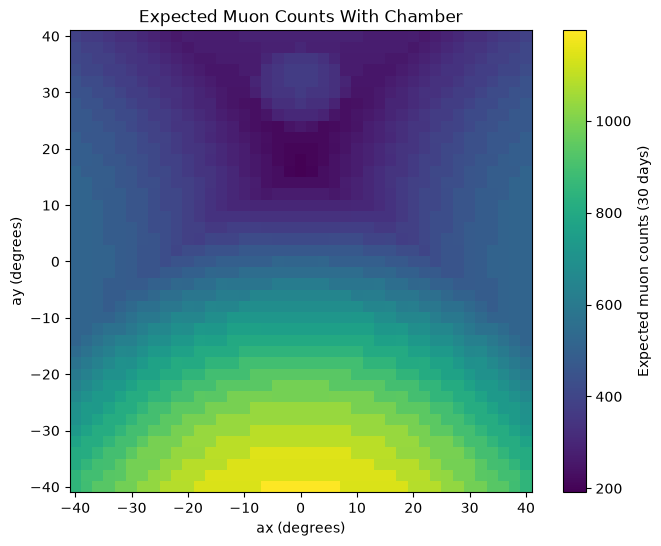

In [4]:
plt.figure(figsize=(8, 6))

plt.imshow(counts_void, origin="lower", extent=extent, cmap="viridis")
plt.colorbar(label="Expected muon counts (30 days)")

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Expected Muon Counts With Chamber")

plt.show()

## Divide out the target shape

Build the same expected-count map for `target.without_void()` and calculate:

`ratio = expected_with_void / expected_without_void`

Away from the chamber the ratio should be close to 1.0. The chamber should appear as an excess above 1.0.


In [5]:
# fill the chamber with rock but keep the rest of the pyramid the same
target0 = target.without_void()

In [6]:
counts_solid, ax_deg, ay_deg = sa.expected_counts(target0, detector, days)

print("30-day count range:", counts_solid.min(), counts_solid.max())
print("Map shape:", counts_solid.shape)

30-day count range: 190.86679260174412 1196.8932172182604
Map shape: (41, 41)


Signal pixel: ax=0°, ay=30°
Expected counts there: 366.8 with, 248.5 without the chamber
Maximum ratio: 1.4758393285204767
Minimum ratio: 1.0


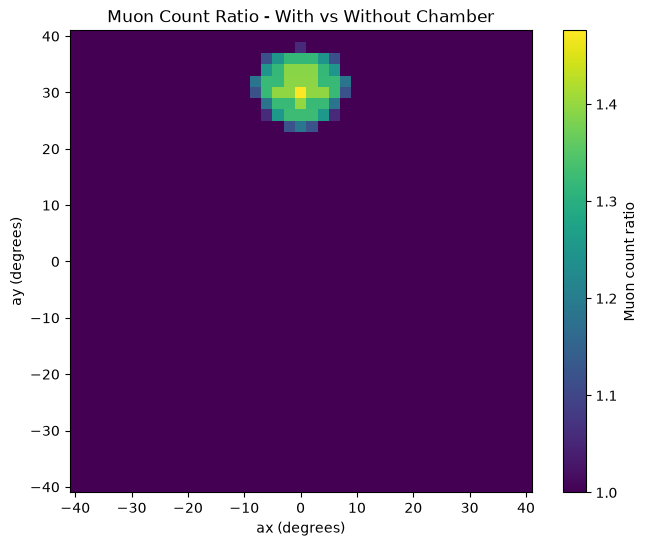

In [7]:
# Compare the muon counts with and without the chamber
ratio = sa.ratio_map(counts_void, counts_solid)
signal_idx = sa.signal_pixel(counts_void, counts_solid)
print(f"Signal pixel: ax={ax_deg[signal_idx]:.0f}°, ay={ay_deg[signal_idx]:.0f}°")
print(f"Expected counts there: {counts_void[signal_idx]:.1f} with, "
      f"{counts_solid[signal_idx]:.1f} without the chamber")

# How big the ratio is
print("Maximum ratio:", np.max(ratio))
print("Minimum ratio:", np.min(ratio))

plt.figure(figsize=(8, 6))

plt.imshow(ratio, origin="lower",
           extent=extent,
           cmap="viridis")

plt.colorbar(label="Muon count ratio")

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Muon Count Ratio - With vs Without Chamber")

plt.show()

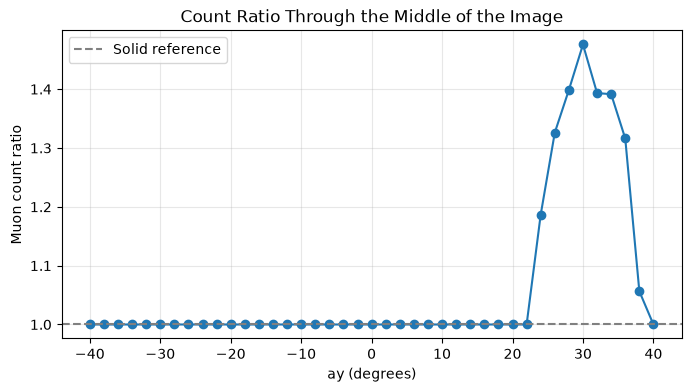

In [8]:
# look down the middle of the map to see the same bump as a line
centre_column = np.argmin(np.abs(ax_deg[0]))
plt.figure(figsize=(8, 4))
plt.plot(ay_deg[:, centre_column], ratio[:, centre_column], marker="o")
plt.axhline(1, color="gray", linestyle="--", label="Solid reference")
plt.xlabel("ay (degrees)")
plt.ylabel("Muon count ratio")
plt.title("Count Ratio Through the Middle of the Image")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Why this ratio is the reconstruction

The raw count map mostly tells you the shape of the pyramid. The ratio removes that known geometric effect and leaves the chamber contrast. This clean ratio is the “after” image for the before-and-after pair.

Do not treat the clean ratio as noisy detector data; notebook 04 adds Poisson fluctuations.
